# Floe Splitting Methods

Sea ice floe detection in the IFT workflow uses a binarize -> split -> evaluate workflow. This notebook demonstrates and tests an improvement to the Buckley et al. erosion-expansion algorithm, incorporating erosion-propagation methods and filtering.

In [1]:
using Pkg
Pkg.activate("../scripts/calval")
using IceFloeTracker
using Images
using DataFrames
using CSVFiles
using CairoMakie
using StatsBase
import IceFloeTracker.Morphology: fill_holes!


  Activating project at `~/Documents/research/calval_tgrs/scripts/calval`


In [2]:
# Load data
dataset = Watkins2026Dataset(;
    url="https://github.com/danielmwatkins/ice-floe-validation-dataset/",
    ref="v0.2",
    cache_dir="/tmp/Watkins2026",
    metadata_path="data/validation_dataset/validation_dataset.csv",
)

#### Run this to use the previously defined test/train split ####
prior_data = DataFrame(load("../data/train_test_split.csv"))
dataset.info[:, :training_sample] = parse.(Bool, prior_data[:, :training_sample])
dataset.info[:, :testing_sample] = parse.(Bool, prior_data[:, :testing_sample])
train_cases = filter(c -> c.training_sample, dataset) 
test_cases = filter(c -> c.testing_sample, dataset);

train_cases.info[:, :lookup_index] = 1:nrow(train_cases.info)
test_cases.info[:, :lookup_index] = 1:nrow(test_cases.info);


In [45]:
img = load("beaufort_sea-2017-06-10.tiff")
binary_img = binarize(Gray.(img), AdaptiveThreshold(; window_size=399, percentage=0));

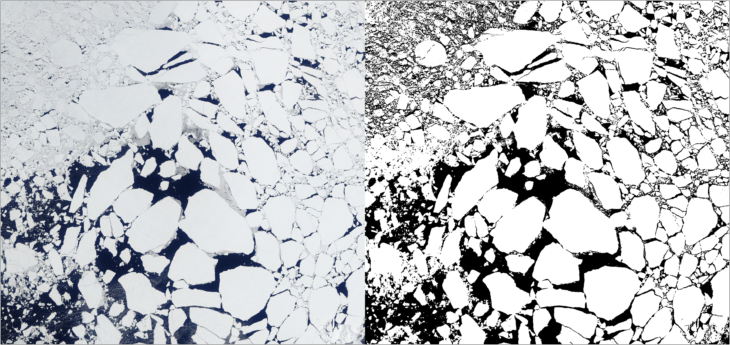

In [99]:
mosaicview(img, binary_img, nrow=1)

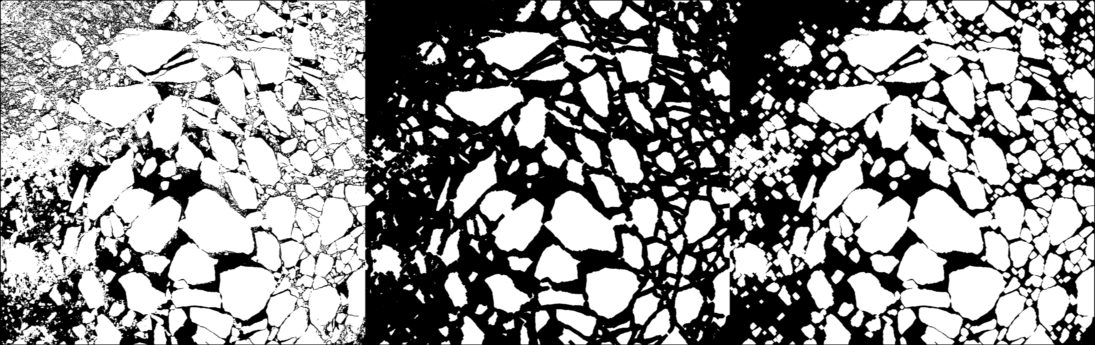

In [100]:
# Run example from Buckley et al. 2024
strel=strel_diamond((3,3))
iters=8
eroded_ice_mask = copy(binary_img)
foreach(_ -> erode!(eroded_ice_mask, copy(eroded_ice_mask), strel), 1:iters)
fill_holes!(eroded_ice_mask, copy(eroded_ice_mask), strel_diamond((3,3)))
markers = label_components(eroded_ice_mask) .+ 1
dilated_ice_mask = copy(eroded_ice_mask)
foreach(_ -> dilate!(dilated_ice_mask, copy(dilated_ice_mask), strel), 1:iters)

mosaicview(binary_img, Gray.(eroded_ice_mask), Gray.(dilated_ice_mask), nrow=1)

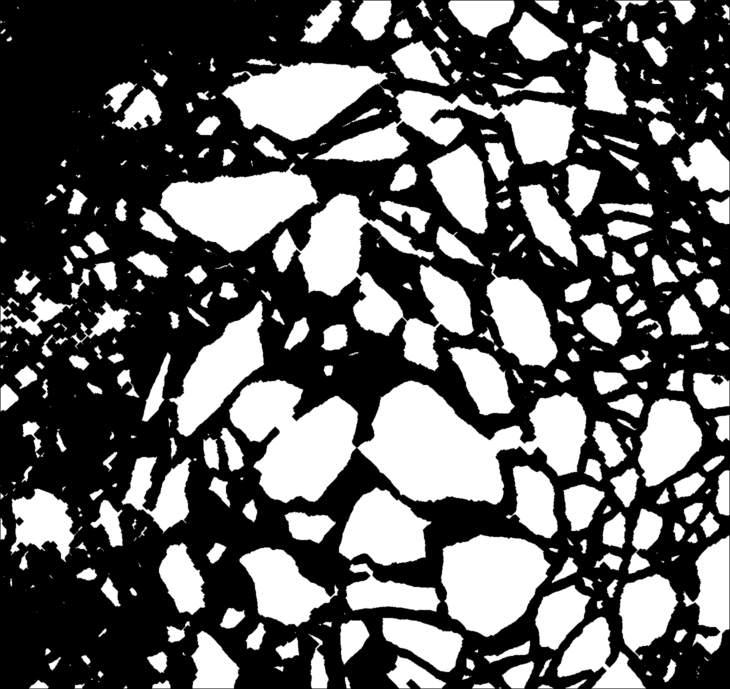

In [105]:
Gray.(eroded_ice_mask)

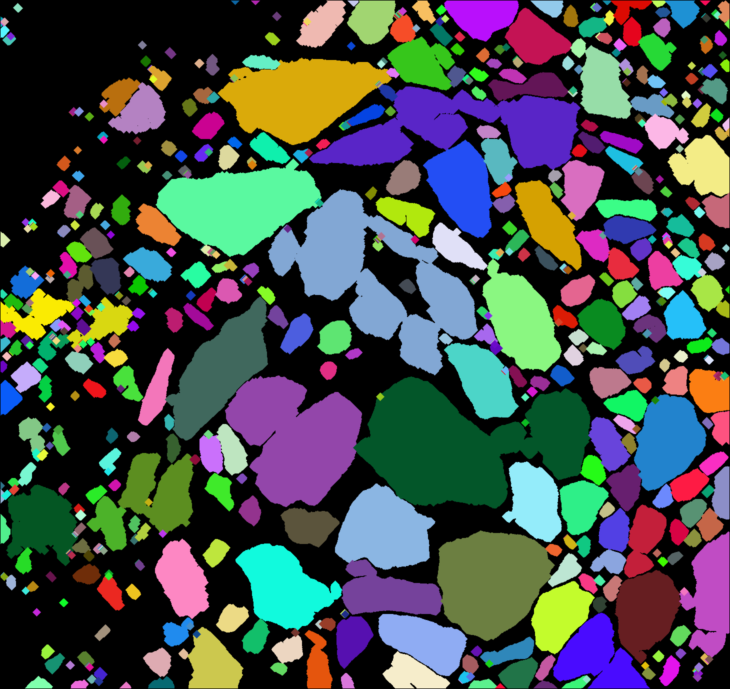

In [103]:
test[dilated_ice_mask .== 0] .= RGB(0)
test

By repeating the erosion operation with the diamond structuring element, we run into the issue that floes remain connected by thin diagonal lines.

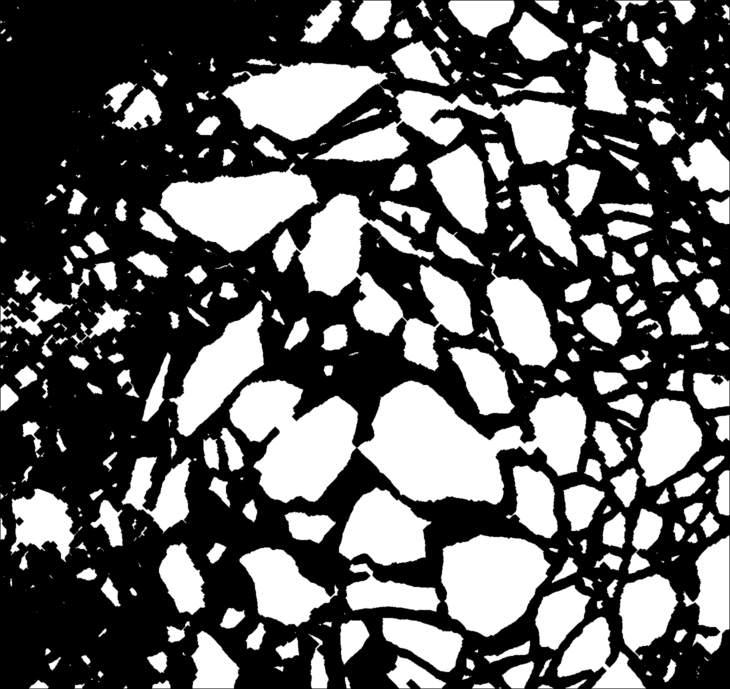

In [60]:
eroded_ice_mask

In [75]:
# An option: Apply opening with a different-shaped structuring element
# with size depending on the number of iterations. This method results in 
# removing the small pieces, which can be a problem for the last stages of 
# re-growing the image.
# opened_markers = opening(eroded_ice_mask, strel_disk(8))

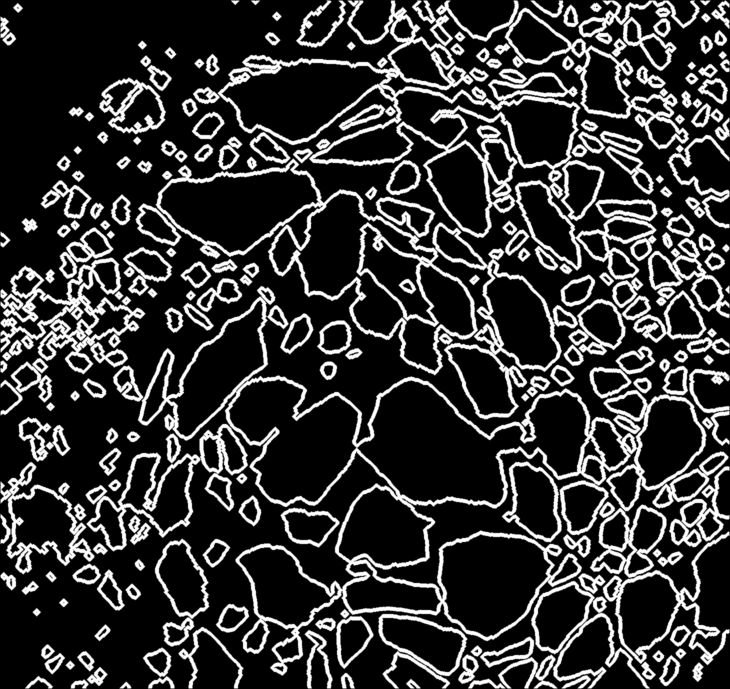

In [76]:
Gray.(unknown)

In [97]:
foreach(_ -> dilate!(markers, copy(markers), strel), 1:iters)


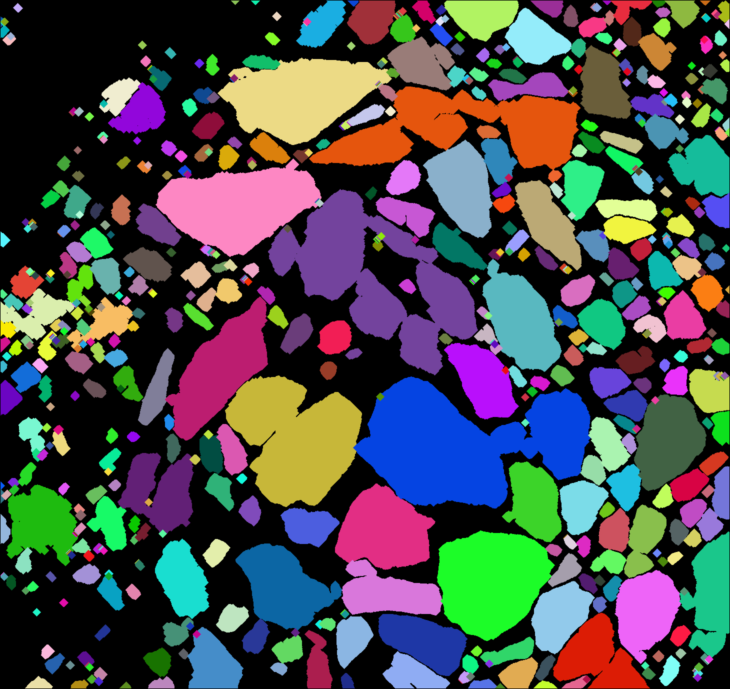

In [98]:
view_seg_random(SegmentedImage(img, markers))

In [166]:
# ebseg python code
import IceFloeTracker.Morphology: fill_holes

function erode_expand_buckley2024(
        gray_img, # image to use in the watershed transformation
        binary_img; # bitmatrix where ice is marked true
        itmin=1, # minimum number of iterations
        itmax=8, # maximum number of iterations
        step=1, # spacing between iterations
        strel=strel_diamond((3,3)),
        minimum_area=16,
        save_figs=true
        )

    input = copy(binary_img)
    input_no = copy(binary_img)
    
    output = zeros(Int64, size(binary_img))
    label_offset = 0
    
    for iters in itmax:-step:itmin
        eroded_ice_mask = copy(binary_img)

        # Note that copy is needed for in-place morphological operations, since
        # the in-place operation will delete the source image along the way.
        
        foreach(_ -> erode!(eroded_ice_mask, copy(eroded_ice_mask), strel), 1:iters)
        fill_holes!(eroded_ice_mask, copy(eroded_ice_mask), strel_diamond((3,3)))
        markers = label_components(eroded_ice_mask) .+ 1
        dilated_ice_mask = copy(eroded_ice_mask)
        foreach(_ -> dilate!(dilated_ice_mask, copy(dilated_ice_mask), strel), 1:iters)

        # Select the pixels between the dilated and the eroded sections.
        # These are where we'll re-grow floes.
        # The phrasing "unknown" is based on the CV2 watershed description
        # (e.g. https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html)
        # Setting the background to 1 helps keep it separate at the end.
        
        unknown = copy(dilated_ice_mask)
        unknown[eroded_ice_mask .> 0] .= 0
        markers[unknown .> 0] .= 0
        
        # Dilating the markers replaces values with the maximum in the neighborhood,
        # which can have surprising results with randomly-labeled data.
        foreach(_ -> dilate!(markers, copy(markers), strel), 1:iters)
            
        # Use the watershed transformation to recover some detail of floe edges
        watershed_labels = labels_map(watershed(complement.(gray_img), markers))
        watershed_labels .-= 1
        
        # Set anything originally classified as water to background
        watershed_labels[binary_img .== 0] .= 0
        
        # Clear objects intersecting the land mask (TBD - no land in this image)

        # Clear objects where we've already got output labels
        watershed_labels[output .> 0] .= 0

        # Re-label since regions often are split up at this stage
        watershed_labels .= label_components(watershed_labels)
        
        # Remove small segments
        remove_small_segments!(watershed_labels, maximum([minimum_area, iters^4]))

        if save_figs
            fname = "identification_round_"*string(iters)*".png"
            save(fname, view_seg_random(SegmentedImage(binary_img, watershed_labels)))
        end

        # Input for next stage:
        # backround in the watershed, positive in the ice mask, positive at beginning of round
        input .= (watershed_labels .== 0) .&& (input .> 0) .&& (binary_img .> 0)

        # Update the output
        new_label_mask = watershed_labels .> 0
        output[new_label_mask] .= watershed_labels[new_label_mask] .+ label_offset
        label_offset = maximum(output)
    end
    output .= label_components(output)
    
    # add min brightness step (TBD)
    
    return output
end

erode_expand_buckley2024 (generic function with 1 method)

In [172]:
@time begin
    test = erode_expand_buckley2024(Gray.(img),
        binary_img; strel=strel_diamond((3,3)), step=1, itmax=8);
end
view_seg_random(SegmentedImage(img, test))

  5.051686 seconds (112.51 M allocations: 8.037 GiB, 23.70% gc time)


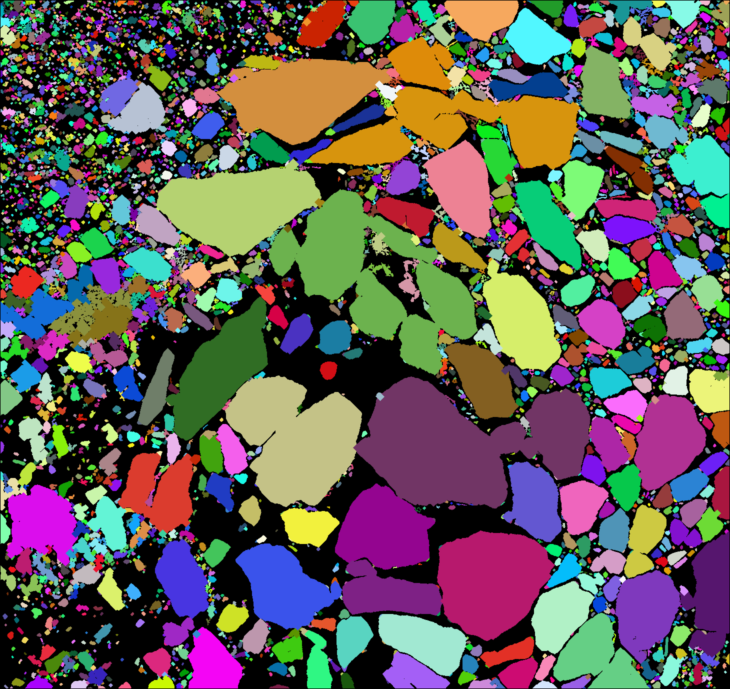

In [173]:
view_seg_random(SegmentedImage(img, test))

Final cleanup from EB paper: remove objects with mean brightness less than 150/255

In [159]:
df = regionprops_table(test; properties=[:label, :area]);

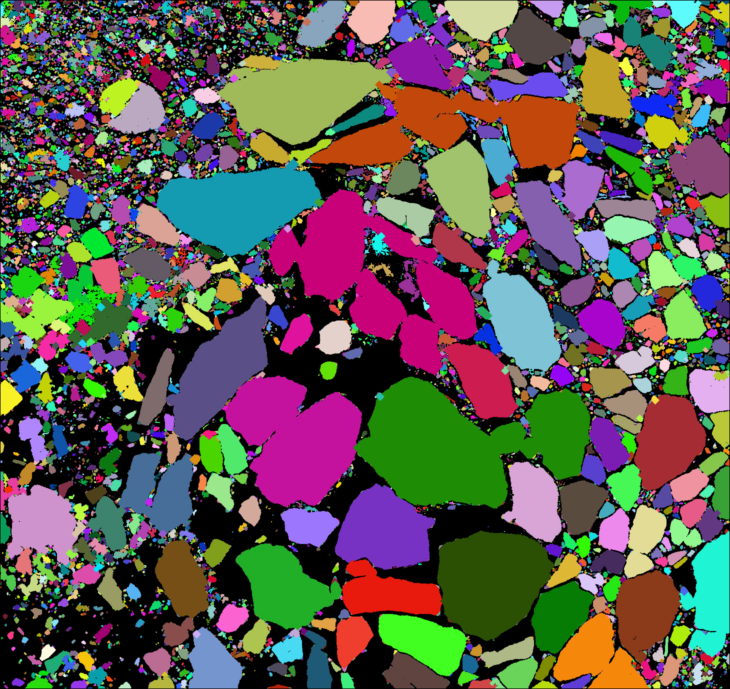

In [139]:
floe_mask = Gray.(view_seg(SegmentedImage(Gray.(red.(img)), test)) .> 150/255)
test[floe_mask .== 0] .= 0
segmented = SegmentedImage(img, test)
view_seg_random(segmented)

In [136]:
segmented

Segmented Image with:
  labels map: 1376×1458 Matrix{Int64}
  number of labels: 26089

In [120]:
@time begin
    test2 = dist_morph_split(binary_img .> 0)
end

  6.356366 seconds (3.26 M allocations: 6.332 GiB, 40.76% gc time, 9.52% compilation time)


1376×1458 Matrix{Int64}:
 0  0  0  0  0  34  34  34  34  34  34  …  1383  1383  1383  1383  1383  1383
 0  0  0  0  0   0  34  34  34  34  34     1383  1383  1383  1383  1383  1383
 0  0  0  0  0   0  34  34  34  34  34     1383  1383  1383  1383  1383  1383
 0  0  0  0  0   0   0  34  34  34  34     1383  1383  1383  1383  1383  1383
 1  0  0  0  0   0   0  34  34  34  34     1383  1383  1383  1383  1383  1383
 1  1  1  0  0   0   0   0  34  34  34  …  1383  1383  1383  1383  1383  1383
 1  1  1  1  1   0   0   0   0   0  34     1383  1383  1383  1383  1383  1383
 1  1  1  1  1   0   0   0   0   0   0     1383  1383  1383  1383  1383  1383
 1  1  1  1  1   1   0   0   0   0   0     1383  1383  1383  1383  1383  1383
 1  1  1  1  1   1   0   0   0   0   0     1383  1383  1383  1383  1383  1383
 1  1  1  1  1   1   1   0   0   0   0  …  1383  1383  1383  1383  1383  1383
 1  1  1  1  1   1   1   0   0   0   0     1383  1383  1383  1383  1383  1383
 1  1  1  1  1   1   1   1   0   0   0 

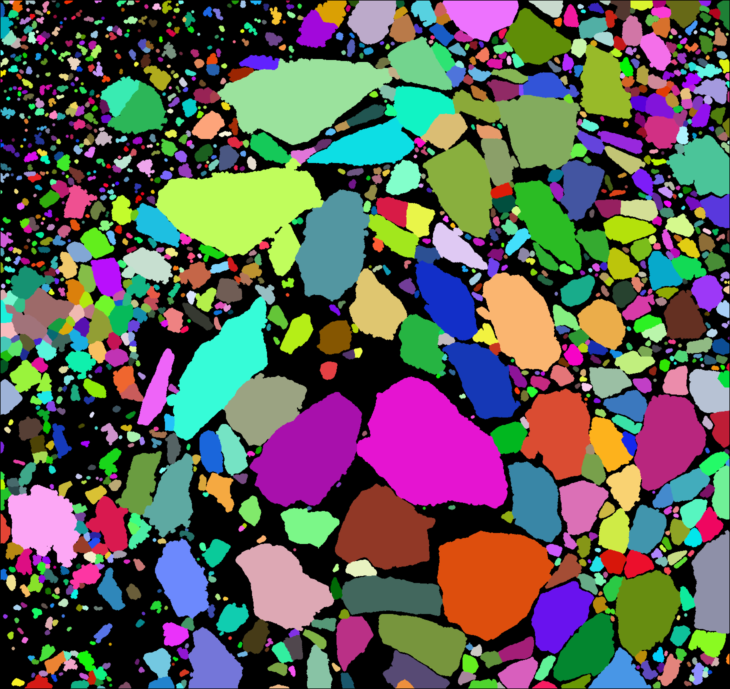

In [121]:
view_seg_random(SegmentedImage(img, label_components(test2)))

In [186]:
# ebseg python code
import IceFloeTracker.Morphology: fill_holes

function erode_expand_buckley2024(
        gray_img, # image to use in the watershed transformation
        binary_img; # bitmatrix where ice is marked true
        itmin=1, # minimum number of iterations
        itmax=8, # maximum number of iterations
        step=1, # spacing between iterations
        strel=strel_diamond((3,3)),
        minimum_area=16,
        save_figs=true
        )

    input = copy(binary_img)
    input_no = copy(binary_img)
    
    output = zeros(Int64, size(binary_img))
    label_offset = 0
    
    for (r, iters) in enumerate(itmax:-step:itmin)
        eroded_ice_mask = copy(binary_img)
        foreach(_ -> erode!(eroded_ice_mask, copy(eroded_ice_mask), strel), 1:iters)
        fill_holes!(eroded_ice_mask, copy(eroded_ice_mask), strel_diamond((3,3)))

        markers = label_components(eroded_ice_mask)
        remove_small_segments!(markers, minimum_area)
        markers .+= 1
        
        dilated_ice_mask = copy(eroded_ice_mask)
        foreach(_ -> dilate!(dilated_ice_mask, copy(dilated_ice_mask), strel), 1:iters)
        
        unknown = copy(dilated_ice_mask)
        unknown[eroded_ice_mask .> 0] .= 0
        markers[unknown .> 0] .= 0
        
        # Dilating the markers replaces values with the maximum in the neighborhood,
        # which can have surprising results with randomly-labeled data.
        foreach(_ -> dilate!(markers, copy(markers), strel), 1:iters)
            
        # Use the watershed transformation to recover some detail of floe edges
        watershed_labels = labels_map(watershed(complement.(gray_img), markers))
        watershed_labels .-= 1
        
        # Set anything originally classified as water to background
        watershed_labels[binary_img .== 0] .= 0
        
        # Clear objects intersecting the land mask (TBD - no land in this image)

        # Clear objects where we've already got output labels
        watershed_labels[output .> 0] .= 0

        # Re-label since regions often are split up at this stage
        watershed_labels .= label_components(watershed_labels)
        
        # Remove small segments
        remove_small_segments!(watershed_labels, maximum([minimum_area, iters^4]))

        if save_figs
            fname = "identification_round_"*string(r)*".png"
            save(fname, view_seg_random(SegmentedImage(binary_img, watershed_labels)))
        end

        # Input for next stage:
        # backround in the watershed, positive in the ice mask, positive at beginning of round
        input .= (watershed_labels .== 0) .&& (input .> 0) .&& (binary_img .> 0)

        # Update the output
        new_label_mask = watershed_labels .> 0
        output[new_label_mask] .= watershed_labels[new_label_mask] .+ label_offset
        label_offset = maximum(output)
    end
    output .= label_components(output)
    
    # add min brightness step (TBD)
    
    return output
end

erode_expand_buckley2024 (generic function with 1 method)

  5.086956 seconds (112.52 M allocations: 8.225 GiB, 23.05% gc time)


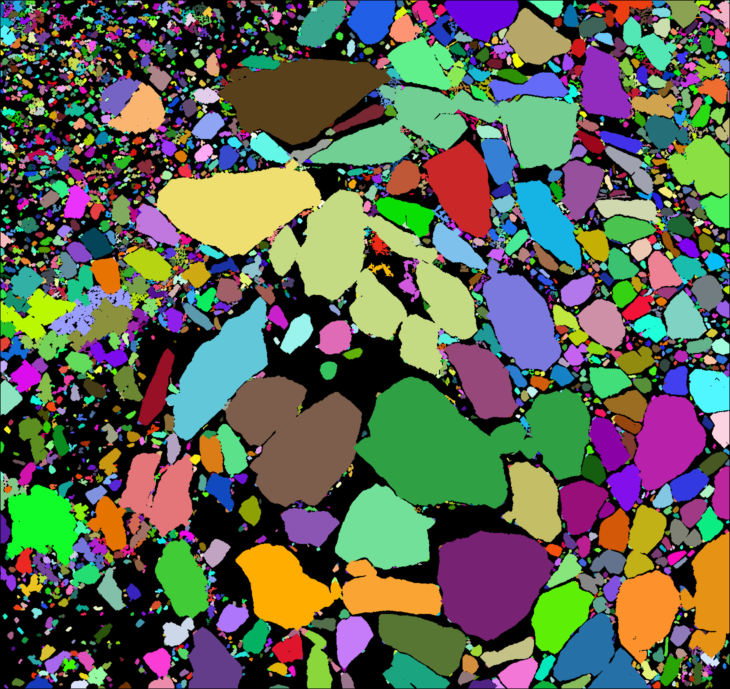

In [188]:
@time begin
    test = erode_expand_buckley2024(Gray.(img),
        binary_img; strel=strel_diamond((3,3)), step=1, itmax=8);
end
view_seg_random(SegmentedImage(img, test))

Moving forward (and to comparison with the distance-transform-based method).

1. It is clear that large floes are not being sufficiently separated. However, the algorithm is reasonably fast, and we can also quickly identify shapes which are